
# Google Play Store Apps and Reviews
## Exploratory Data Analysis

**Course:** Exploratory Data Analysis  
**Course Code:** CSB314  
**Assessment:** Minor Project 02 (CA 03)

### 1. Introduction

The Google Play Store contains thousands of Android applications belonging to different categories. These applications differ in their ratings, number of installations, prices, sizes and user reviews.

This project aims to perform Exploratory Data Analysis (EDA) on Google Play Store applications and their user reviews using Python.

The analysis covers data understanding, data quality assessment, feature engineering, grouping and aggregation, pivot tables, data reshaping, data integration, descriptive statistics, distribution analysis, sampling, correlation and data validation.

The project uses Pandas and NumPy to inspect, clean, transform and analyse the datasets. Results are presented through tables and numerical summaries.


## 2. Problem Statement

The Google Play Store contains applications with different characteristics, but it is not always easy to understand how factors such as category, price, size and installations are related to app ratings and user reviews.

The purpose of this project is to explore the dataset, identify patterns and understand the characteristics of applications available on the Google Play Store.

### 3. Analytical Objectives

1. Analyse application ratings across different categories.
2. Examine the relationship between app price, size, installations and ratings.
3. Identify the most popular application categories.
4. Analyse positive and negative user reviews.
5. Perform data cleaning and feature engineering.
6. Apply descriptive statistics and distribution analysis.
7. Identify correlations and potential outliers.
8. Evaluate the quality and consistency of the dataset.



## 4. Dataset Source and Description

The dataset used in this project is the Google Play Store Apps and Reviews dataset obtained from Kaggle.

**Dataset Source:** https://www.kaggle.com/datasets/lava18/google-play-store-apps

The dataset contains two related files:

1. Google Play Store Apps – Contains application details such as app name, category, rating, reviews, size, installations, price and last updated date.
2. Google Play Store User Reviews – Contains translated user reviews, sentiment labels, sentiment polarity and sentiment subjectivity.

The two datasets are related through the common column named `App`.

These datasets will be used to analyse application characteristics and user feedback.


In [396]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# pd.set_option("display.max_columns", None)
# pd.set_option("display.max_rows", 20)

print("Required libraries imported successfully!")

Required libraries imported successfully!


In [397]:
# Loading the original datasets
# Keep both CSV files in the same folder as this notebook.

apps_raw = pd.read_csv("googleplaystore.csv")
reviews_raw = pd.read_csv("17-googleplaystore_user_reviews.csv")

# Preserve the original data and create working copies.
apps = apps_raw.copy()
reviews = reviews_raw.copy()

print("Datasets loaded successfully!")

Datasets loaded successfully!


## 5. Objective
To understand the structure, dimensions and data types of both datasets before performing further analysis.

### Concept
Dataset exploration helps identify the number of records, columns, data types and missing values.

### Methodology
The `head()`, `shape`, `dtypes` and `info()` functions were used to examine both datasets.

### Output and Observations
1. `head()` displayed the first five records.
2. `shape` showed the number of rows and columns.
3. `dtypes` identified the data types of each column.
4. `info()` displayed column details and non-null counts.
5. Both datasets contain an `App` column for data integration.
6. Some numerical columns were initially stored as object data types and required conversion.

### Conclusion
Both datasets were successfully explored before further analysis.

In [398]:
# Checking dataset dimensions

print("Google Play Store Apps Dataset")
print(apps.shape)

print("\nGoogle Play Store Reviews Dataset")
print(reviews.shape)

Google Play Store Apps Dataset
(10841, 13)

Google Play Store Reviews Dataset
(64295, 5)


In [399]:
print("First five records of Google Play Store Apps:")
display(apps.head())

print("First five records of User Reviews:")
display(reviews.head())

First five records of Google Play Store Apps:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


First five records of User Reviews:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [400]:
print("Data types of Apps dataset:")
display(apps.dtypes)

print("Data types of Reviews dataset:")
display(reviews.dtypes)

Data types of Apps dataset:


App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

Data types of Reviews dataset:


App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

In [401]:
print("Information about Apps dataset:")
apps.info()

print("\nInformation about Reviews dataset:")
reviews.info()

Information about Apps dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB

Information about Reviews dataset:
<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column  

### Output and Observations

1. The `head()` function displayed the first five records of both datasets.
2. The `shape` attribute showed the number of rows and columns.
3. The `dtypes` function identified the data types of each column.
4. The `info()` function provided column details and non-null counts.
5. Both datasets contain an `App` column, which can be used for data integration.
6. Some numerical columns were stored as object data types and required conversion.

**Conclusion:** Both datasets were successfully explored, and their structure was understood before further analysis.

# 6. Data Quality Assessment

## 6.1 Objective

The objective of this section is to examine the quality of the Google Play Store Apps and User Reviews datasets before performing further analysis.

We will identify missing values, duplicate records, incorrect data types and potentially invalid values.

## 6.2 Concept

Data quality assessment is the process of checking whether a dataset is complete, consistent, valid and reliable.

The major aspects examined in this project are:

- **Completeness:** Checking whether any values are missing.
- **Consistency:** Checking whether values follow a consistent format.
- **Validity:** Checking whether values fall within acceptable ranges.
- **Duplicates:** Identifying repeated rows and records.
- **Data types:** Checking whether columns have appropriate data types.

## 6.3 Methodology

The original datasets are preserved in `apps_raw` and `reviews_raw`, while the working copies are stored in `apps` and `reviews`.

We will use Pandas functions such as `isnull()`, `sum()`, `duplicated()` and `dtypes` to examine data quality.

No records will be removed or changed during this initial assessment.

In [402]:
# Checking missing values in Apps Dataset
print("Missing Values in Apps Dataset:")
display(apps.isnull().sum())

# Checking missing values in Reviews Dataset
print("\nMissing Values in Reviews Dataset:")
display(reviews.isnull().sum())

Missing Values in Apps Dataset:


App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


Missing Values in Reviews Dataset:


App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

In [403]:
# Missing value percentage in Apps Dataset
apps_missing_percentage = (apps.isnull().sum() / len(apps)) * 100

print("Missing Value Percentage - Apps Dataset:")
display(apps_missing_percentage.round(2))

# Missing value percentage in Reviews Dataset
reviews_missing_percentage = (reviews.isnull().sum() / len(reviews)) * 100

print("\nMissing Value Percentage - Reviews Dataset:")
display(reviews_missing_percentage.round(2))

Missing Value Percentage - Apps Dataset:


App                0.00
Category           0.00
Rating            13.60
Reviews            0.00
Size               0.00
Installs           0.00
Type               0.01
Price              0.00
Content Rating     0.01
Genres             0.00
Last Updated       0.00
Current Ver        0.07
Android Ver        0.03
dtype: float64


Missing Value Percentage - Reviews Dataset:


App                        0.00
Translated_Review         41.79
Sentiment                 41.78
Sentiment_Polarity        41.78
Sentiment_Subjectivity    41.78
dtype: float64

In [404]:
# Checking completely duplicated rows
print("Duplicate Rows in Apps Dataset:", apps.duplicated().sum())

print("Duplicate Rows in Reviews Dataset:", reviews.duplicated().sum())

# Checking duplicate App names
print("\nDuplicate App Names in Apps Dataset:")
print(apps["App"].duplicated().sum())

Duplicate Rows in Apps Dataset: 483
Duplicate Rows in Reviews Dataset: 33616

Duplicate App Names in Apps Dataset:
1181


In [405]:
print("Apps Dataset Data Types:")
display(apps.dtypes)

print("\nReviews Dataset Data Types:")
display(reviews.dtypes)

Apps Dataset Data Types:


App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object


Reviews Dataset Data Types:


App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

# 7. Feature Engineering

## 7.1 Objective

The objective of feature engineering is to create new meaningful variables from the existing columns of the Google Play Store dataset.

These newly created features will help us understand app pricing, popularity, ratings and update patterns more effectively.

## 7.2 Concept

Feature engineering is the process of transforming existing data into new features that provide additional information for analysis.

For this project, we will create features using app price, number of installs, ratings, and last updated dates.

## 7.3 Methodology

The following features will be created:

1. **Price Category:** Classifies applications as Free or Paid.
2. **Install Category:** Groups applications according to their number of installs.
3. **Rating Category:** Classifies applications based on their average rating.
4. **Last Updated Year:** Extracts the year from the application's last updated date.

Before creating these features, we will inspect the relevant columns and convert them into suitable data types wherever necessary.

In [406]:
# Displaying columns required for feature engineering

feature_columns = ["App", "Price", "Installs", "Rating", "Last Updated"]

display(apps[feature_columns].head(10))

# Checking data types
display(apps[feature_columns].dtypes)

,App,Price,Installs,Rating,Last Updated
0,Photo Editor & Candy Camera & Grid & ScrapBook,0,"10,000+",4.1,"January 7, 2018"
1,Coloring book moana,0,"500,000+",3.9,"January 15, 2018"
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",0,"5,000,000+",4.7,"August 1, 2018"
3,Sketch - Draw & Paint,0,"50,000,000+",4.5,"June 8, 2018"
4,Pixel Draw - Number Art Coloring Book,0,"100,000+",4.3,"June 20, 2018"
5,Paper flowers instructions,0,"50,000+",4.4,"March 26, 2017"
6,Smoke Effect Photo Maker - Smoke Editor,0,"50,000+",3.8,"April 26, 2018"
7,Infinite Painter,0,"1,000,000+",4.1,"June 14, 2018"
8,Garden Coloring Book,0,"1,000,000+",4.4,"September 20, 2017"
9,Kids Paint Free - Drawing Fun,0,"10,000+",4.7,"July 3, 2018"


App                 str
Price               str
Installs            str
Rating          float64
Last Updated        str
dtype: object

In [407]:
# Converting Price column into numeric values
apps["Price"] = (
    apps["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

apps["Price"] = pd.to_numeric(apps["Price"], errors="coerce")

# Creating Price Category
apps["Price_Category"] = apps["Price"].apply(
    lambda price: "Free" if price == 0 else
    ("Paid" if price > 0 else "Unknown")
)

# Displaying results
display(apps[["App", "Price", "Price_Category"]].head(10))

,App,Price,Price_Category
0,Photo Editor & Candy Camera & Grid & ScrapBook,0.0,Free
1,Coloring book moana,0.0,Free
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",0.0,Free
3,Sketch - Draw & Paint,0.0,Free
4,Pixel Draw - Number Art Coloring Book,0.0,Free
5,Paper flowers instructions,0.0,Free
6,Smoke Effect Photo Maker - Smoke Editor,0.0,Free
7,Infinite Painter,0.0,Free
8,Garden Coloring Book,0.0,Free
9,Kids Paint Free - Drawing Fun,0.0,Free


In [408]:
# Cleaning the Installs column
apps["Installs"] = (
    apps["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

apps["Installs"] = pd.to_numeric(apps["Installs"], errors="coerce")

# Creating Install Category
apps["Install_Category"] = pd.cut(
    apps["Installs"],
    bins=[-1, 100000, 1000000, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Displaying results
display(apps[["App", "Installs", "Install_Category"]].head(10))

,App,Installs,Install_Category
0,Photo Editor & Candy Camera & Grid & ScrapBook,10000.0,Low
1,Coloring book moana,500000.0,Medium
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",5000000.0,High
3,Sketch - Draw & Paint,50000000.0,High
4,Pixel Draw - Number Art Coloring Book,100000.0,Low
5,Paper flowers instructions,50000.0,Low
6,Smoke Effect Photo Maker - Smoke Editor,50000.0,Low
7,Infinite Painter,1000000.0,Medium
8,Garden Coloring Book,1000000.0,Medium
9,Kids Paint Free - Drawing Fun,10000.0,Low


In [409]:
# Creating Rating Category
apps["Rating_Category"] = pd.cut(
    apps["Rating"],
    bins=[0, 2.5, 3.5, 4.5, 5],
    labels=["Poor", "Average", "Good", "Excellent"],
    include_lowest=True
)

# Displaying results
display(apps[["App", "Rating", "Rating_Category"]].head(10))

,App,Rating,Rating_Category
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,Good
1,Coloring book moana,3.9,Good
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,Excellent
3,Sketch - Draw & Paint,4.5,Good
4,Pixel Draw - Number Art Coloring Book,4.3,Good
5,Paper flowers instructions,4.4,Good
6,Smoke Effect Photo Maker - Smoke Editor,3.8,Good
7,Infinite Painter,4.1,Good
8,Garden Coloring Book,4.4,Good
9,Kids Paint Free - Drawing Fun,4.7,Excellent


In [410]:
# Converting Last Updated into datetime format
apps["Last Updated"] = pd.to_datetime(
    apps["Last Updated"],
    errors="coerce"
)

# Extracting year
apps["Last_Updated_Year"] = apps["Last Updated"].dt.year

# Displaying results
display(apps[["App", "Last Updated", "Last_Updated_Year"]].head(10))

,App,Last Updated,Last_Updated_Year
0,Photo Editor & Candy Camera & Grid & ScrapBook,2018-01-07,2018.0
1,Coloring book moana,2018-01-15,2018.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",2018-08-01,2018.0
3,Sketch - Draw & Paint,2018-06-08,2018.0
4,Pixel Draw - Number Art Coloring Book,2018-06-20,2018.0
5,Paper flowers instructions,2017-03-26,2017.0
6,Smoke Effect Photo Maker - Smoke Editor,2018-04-26,2018.0
7,Infinite Painter,2018-06-14,2018.0
8,Garden Coloring Book,2017-09-20,2017.0
9,Kids Paint Free - Drawing Fun,2018-07-03,2018.0


## 7.4 Summary of Engineered Features

Four new features have been created using the existing columns of the Google Play Store dataset.

- `Price_Category` represents whether an application is free or paid.
- `Install_Category` represents the installation level of an application.
- `Rating_Category` represents the quality category based on app ratings.
- `Last_Updated_Year` represents the year in which an application was last updated.

These features will be used in subsequent grouping, aggregation and statistical comparisons.

## 7.5 Observations

The tables generated above show the new categories and extracted update year for the first ten application records. The category columns preserve missing or invalid source values as an unknown/missing classification instead of treating them as valid observations.

## 7.6 Decision

The newly created features will be retained in the working dataset for further analysis. Missing or invalid values will be handled according to the requirements of each subsequent analysis.

## 7.7 Conclusion

Feature engineering has transformed existing application information into four additional analytical features. These features provide a better foundation for exploring patterns in the Google Play Store dataset.

# 8. Grouping and Aggregation

## 8.1 Objective

The objective of this section is to analyse the Google Play Store applications by grouping them into different categories and calculating useful statistical measures.

## 8.2 Concept

Grouping and aggregation are techniques used to summarise large datasets.

- **groupby():** Divides data into groups based on one or more columns.
- **agg():** Applies multiple aggregation functions, such as count, mean, median, minimum and maximum.
- **transform():** Performs group-level calculations and returns results aligned with the original rows.

## 8.3 Methodology

In this section, applications will be grouped according to their categories.

We will calculate the number of applications, average rating, average installations and other statistical measures.

We will also use transform() to calculate the average rating of each category and add it back to the original dataset.

In [411]:
# Counting applications in each category

category_counts = apps.groupby("Category")["App"].count().sort_values(ascending=False)

display(category_counts)

Category
FAMILY                 1972
GAME                   1144
TOOLS                   843
MEDICAL                 463
BUSINESS                460
PRODUCTIVITY            424
PERSONALIZATION         392
COMMUNICATION           387
SPORTS                  384
LIFESTYLE               382
FINANCE                 366
HEALTH_AND_FITNESS      341
PHOTOGRAPHY             335
SOCIAL                  295
NEWS_AND_MAGAZINES      283
SHOPPING                260
TRAVEL_AND_LOCAL        258
DATING                  234
BOOKS_AND_REFERENCE     231
VIDEO_PLAYERS           175
EDUCATION               156
ENTERTAINMENT           149
MAPS_AND_NAVIGATION     137
FOOD_AND_DRINK          127
HOUSE_AND_HOME           88
LIBRARIES_AND_DEMO       85
AUTO_AND_VEHICLES        85
WEATHER                  82
ART_AND_DESIGN           65
EVENTS                   64
PARENTING                60
COMICS                   60
BEAUTY                   53
1.9                       1
Name: App, dtype: int64

In [412]:
# Applying multiple aggregation functions

category_summary = apps.groupby("Category").agg(
    Total_Apps=("App", "count"),
    Average_Rating=("Rating", "mean"),
    Median_Rating=("Rating", "median"),
    Average_Installs=("Installs", "mean"),
    Maximum_Installs=("Installs", "max")
)

display(category_summary.round(2))

,Total_Apps,Average_Rating,Median_Rating,Average_Installs,Maximum_Installs
Category,,,,,
1.9,1,19.00,19.0,NaN,NaN
ART_AND_DESIGN,65,4.36,4.4,1912893.85,5.000000e+07
AUTO_AND_VEHICLES,85,4.19,4.3,625061.31,1.000000e+07
BEAUTY,53,4.28,4.3,513151.89,1.000000e+07
BOOKS_AND_REFERENCE,231,4.35,4.5,8318050.11,1.000000e+09
BUSINESS,460,4.12,4.3,2178075.79,1.000000e+08
COMICS,60,4.16,4.4,934769.17,1.000000e+07
COMMUNICATION,387,4.16,4.3,84359886.95,1.000000e+09
DATING,234,3.97,4.1,1129533.36,1.000000e+07


In [413]:
# Calculating average rating for each category
# and assigning it to every app in that category

apps["Category_Average_Rating"] = (
    apps.groupby("Category")["Rating"].transform("mean")
)

display(
    apps[["App", "Category", "Rating", "Category_Average_Rating"]].head(10)
)

,App,Category,Rating,Category_Average_Rating
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,4.358065
1,Coloring book moana,ART_AND_DESIGN,3.9,4.358065
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,4.358065
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,4.358065
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,4.358065
5,Paper flowers instructions,ART_AND_DESIGN,4.4,4.358065
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,4.358065
7,Infinite Painter,ART_AND_DESIGN,4.1,4.358065
8,Garden Coloring Book,ART_AND_DESIGN,4.4,4.358065
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,4.358065


In [414]:
# Selecting the 10 categories with the highest number of apps

top_categories = category_counts.head(10)

display(top_categories)

Category
FAMILY             1972
GAME               1144
TOOLS               843
MEDICAL             463
BUSINESS            460
PRODUCTIVITY        424
PERSONALIZATION     392
COMMUNICATION       387
SPORTS              384
LIFESTYLE           382
Name: App, dtype: int64

## 8.4 Output and Interpretation

The category summary shows the number of apps in each category and the available rating and installation statistics. The top-ten table ranks categories by app count, not by rating or popularity.

## 8.5 Observations

Compare category size with average and median ratings. Average installations can be affected by a small number of very popular apps, so interpret them alongside the other summary measures.

## 8.6 Decision

Retain the category counts and aggregation results for later comparisons. A larger number of apps does not automatically mean a category performs better.

## 8.7 Conclusion

Grouping and aggregation summarise application data and make differences between categories easier to examine.

# 9. Pivot Tables and Crosstab

## 9.1 Objective

The objective of this section is to summarise and compare application data using pivot tables and cross-tabulation.

## 9.2 Concept

A pivot table summarises numerical data across different categorical variables.

A crosstabulation table displays the frequency distribution between two or more categorical variables.

The main functions used are:

- **pivot_table():** Calculates statistical summaries across rows and columns.
- **crosstab():** Displays the frequency relationship between categorical variables.

## 9.3 Methodology

In this section, we will:

1. Create a pivot table to compare average app ratings across categories and price categories.
2. Create a crosstab to examine the distribution of free and paid applications across categories.
3. Calculate percentages to understand the distribution more clearly.

In [415]:
# Average rating by app category and price category

rating_pivot = pd.pivot_table(
    apps,
    values="Rating",
    index="Category",
    columns="Price_Category",
    aggfunc="mean",
    observed=False
)

display(rating_pivot.round(2))

Price_Category,Free,Paid,Unknown
Category,,,
1.9,NaN,NaN,19.0
ART_AND_DESIGN,4.34,4.73,NaN
AUTO_AND_VEHICLES,4.18,4.60,NaN
BEAUTY,4.28,NaN,NaN
BOOKS_AND_REFERENCE,4.35,4.28,NaN
BUSINESS,4.12,4.20,NaN
COMICS,4.16,NaN,NaN
COMMUNICATION,4.17,4.06,NaN
DATING,3.98,3.62,NaN


In [416]:
# Frequency distribution of app categories and price categories

category_price_table = pd.crosstab(
    apps["Category"],
    apps["Price_Category"]
)

display(category_price_table)

Price_Category,Free,Paid,Unknown
Category,,,
1.9,0,0,1
ART_AND_DESIGN,62,3,0
AUTO_AND_VEHICLES,82,3,0
BEAUTY,53,0,0
BOOKS_AND_REFERENCE,203,28,0
BUSINESS,446,14,0
COMICS,60,0,0
COMMUNICATION,360,27,0
DATING,227,7,0


In [417]:
# Calculating row-wise percentages

category_price_percentage = pd.crosstab(
    apps["Category"],
    apps["Price_Category"],
    normalize="index"
) * 100

display(category_price_percentage.round(2))

Price_Category,Free,Paid,Unknown
Category,,,
1.9,0.00,0.00,100.0
ART_AND_DESIGN,95.38,4.62,0.0
AUTO_AND_VEHICLES,96.47,3.53,0.0
BEAUTY,100.00,0.00,0.0
BOOKS_AND_REFERENCE,87.88,12.12,0.0
BUSINESS,96.96,3.04,0.0
COMICS,100.00,0.00,0.0
COMMUNICATION,93.02,6.98,0.0
DATING,97.01,2.99,0.0


In [418]:
# Creating a crosstab with row and column totals

category_price_totals = pd.crosstab(
    apps["Category"],
    apps["Price_Category"],
    margins=True,
    margins_name="Total"
)

display(category_price_totals)

Price_Category,Free,Paid,Unknown,Total
Category,,,,
1.9,0,0,1,1
ART_AND_DESIGN,62,3,0,65
AUTO_AND_VEHICLES,82,3,0,85
BEAUTY,53,0,0,53
BOOKS_AND_REFERENCE,203,28,0,231
BUSINESS,446,14,0,460
COMICS,60,0,0,60
COMMUNICATION,360,27,0,387
DATING,227,7,0,234


## 9.4 Output and Interpretation

The pivot table compares average ratings across app categories and price groups. The crosstab reports the number of free, paid and unknown-price apps in each category, while the percentage table shows each price group's share within a category.

## 9.5 Observations

Use counts to compare the number of records and percentages to compare category composition. Use the pivot table to compare average ratings. An empty pivot-table cell indicates that no valid observations were available for that combination; it does not represent a rating of zero.

## 9.6 Decision

Retain the pivot table and crosstab as complementary summaries of ratings, counts and within-category proportions.

## 9.7 Conclusion

Pivot tables and crosstabulation help compare numerical summaries and categorical frequencies across app categories and pricing groups.

# 10. Data Reshaping

## 10.1 Objective

The objective of this section is to understand how data can be reorganised into different structures to make analysis easier.

## 10.2 Concept

Data reshaping is the process of changing the layout of a dataset without necessarily changing the information it contains.

The following Pandas functions will be used:

- **melt():** Converts wide-format data into long-format data.
- **pivot():** Converts long-format data into wide-format data.
- **stack():** Converts columns into an additional index level.
- **unstack():** Converts an index level back into columns.

## 10.3 Methodology

We will create a small summary dataset using app categories and their average ratings and installations.

This summary will be used to demonstrate the reshaping functions without modifying the original application records.

In [419]:
# Creating a small dataset for reshaping demonstrations

reshape_data = (
    apps.groupby("Category")
    .agg(
        Average_Rating=("Rating", "mean"),
        Average_Installs=("Installs", "mean")
    )
    .reset_index()
)

# Selecting the first 5 categories
reshape_data = reshape_data.head(5)

display(reshape_data)

,Category,Average_Rating,Average_Installs
0,1.9,19.000000,NaN
1,ART_AND_DESIGN,4.358065,1.912894e+06
2,AUTO_AND_VEHICLES,4.190411,6.250613e+05
3,BEAUTY,4.278571,5.131519e+05
4,BOOKS_AND_REFERENCE,4.346067,8.318050e+06


In [420]:
# Converting wide-format data into long-format data

melted_data = pd.melt(
    reshape_data,
    id_vars=["Category"],
    value_vars=["Average_Rating", "Average_Installs"],
    var_name="Metric",
    value_name="Value"
)

display(melted_data)

,Category,Metric,Value
0,1.9,Average_Rating,1.900000e+01
1,ART_AND_DESIGN,Average_Rating,4.358065e+00
2,AUTO_AND_VEHICLES,Average_Rating,4.190411e+00
3,BEAUTY,Average_Rating,4.278571e+00
4,BOOKS_AND_REFERENCE,Average_Rating,4.346067e+00
5,1.9,Average_Installs,NaN
6,ART_AND_DESIGN,Average_Installs,1.912894e+06
7,AUTO_AND_VEHICLES,Average_Installs,6.250613e+05
8,BEAUTY,Average_Installs,5.131519e+05
9,BOOKS_AND_REFERENCE,Average_Installs,8.318050e+06


In [421]:
# Converting long-format data back into wide-format data

pivoted_data = melted_data.pivot(
    index="Category",
    columns="Metric",
    values="Value"
)

display(pivoted_data)

Metric,Average_Installs,Average_Rating
Category,,
1.9,NaN,19.000000
ART_AND_DESIGN,1.912894e+06,4.358065
AUTO_AND_VEHICLES,6.250613e+05,4.190411
BEAUTY,5.131519e+05,4.278571
BOOKS_AND_REFERENCE,8.318050e+06,4.346067


In [422]:
# Converting columns into an additional index level

stacked_data = pivoted_data.stack(future_stack=True)

display(stacked_data)

Category             Metric          
1.9                  Average_Installs             NaN
                     Average_Rating      1.900000e+01
ART_AND_DESIGN       Average_Installs    1.912894e+06
                     Average_Rating      4.358065e+00
AUTO_AND_VEHICLES    Average_Installs    6.250613e+05
                     Average_Rating      4.190411e+00
BEAUTY               Average_Installs    5.131519e+05
                     Average_Rating      4.278571e+00
BOOKS_AND_REFERENCE  Average_Installs    8.318050e+06
                     Average_Rating      4.346067e+00
dtype: float64

In [423]:
# Converting the stacked data back into columns

unstacked_data = stacked_data.unstack()

display(unstacked_data)

Metric,Average_Installs,Average_Rating
Category,,
1.9,NaN,19.000000
ART_AND_DESIGN,1.912894e+06,4.358065
AUTO_AND_VEHICLES,6.250613e+05,4.190411
BEAUTY,5.131519e+05,4.278571
BOOKS_AND_REFERENCE,8.318050e+06,4.346067


## 10.4 Output and Interpretation

`melt()` converts the category summary from wide to long format by placing measure names in one column and their values in another. `pivot()` reconstructs the wide table, while `stack()` and `unstack()` move measure labels between columns and index levels.

## 10.5 Observations

The same summary information is displayed in different layouts. The number of rows may change during reshaping because one wide row can become multiple long rows; this does not mean that the underlying measurements have changed.

## 10.6 Decision

The reshaped DataFrames are retained as temporary demonstrations. The original Apps dataset remains unchanged.

## 10.7 Conclusion

Data reshaping provides flexibility for analysis and reporting by converting information between wide, long and hierarchical formats.

# 11. Data Integration

## 11.1 Objective

The objective of this section is to integrate the Google Play Store Apps dataset with the User Reviews dataset to create a combined dataset for further analysis.

## 11.2 Concept

Data integration is the process of combining information from multiple related datasets.

In this project:

- The Apps dataset contains application-level information.
- The Reviews dataset contains user feedback and sentiment information.
- The common column used for integration is `App`.

The Apps dataset contains one record per application in many cases, whereas the Reviews dataset may contain multiple reviews for the same application.

Therefore, the relationship between the datasets is generally one-to-many.

## 11.3 Methodology

The following steps will be performed:

1. Identify the common key between the datasets.
2. Check duplicate application names.
3. Summarise review information for each application.
4. Merge the two datasets using the common key.
5. Validate the merge and examine unmatched records.

The original datasets will be preserved throughout this process.

In [424]:
# Identifying common columns

common_columns = set(apps.columns).intersection(set(reviews.columns))

print("Common Columns:", common_columns)

# Checking duplicate application names
print("\nDuplicate App Names in Apps Dataset:", apps["App"].duplicated().sum())

print("Duplicate App Names in Reviews Dataset:", reviews["App"].duplicated().sum())

Common Columns: {'App'}

Duplicate App Names in Apps Dataset: 1181
Duplicate App Names in Reviews Dataset: 63221


In [425]:
# Displaying review-related columns

display(reviews.head())

# Checking available sentiment categories
print("Sentiment Distribution:")
display(reviews["Sentiment"].value_counts(dropna=False))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


Sentiment Distribution:


Sentiment
NaN         26863
Positive    23998
Negative     8271
Neutral      5163
Name: count, dtype: int64

In [426]:
# Converting sentiment columns into numeric values - it converts valid numeric values into numbers and changes invalid text values into NaN (missing values), rather than stopping the code with an error.

reviews["Sentiment_Polarity"] = pd.to_numeric(
    reviews["Sentiment_Polarity"], errors="coerce"
)

reviews["Sentiment_Subjectivity"] = pd.to_numeric(
    reviews["Sentiment_Subjectivity"], errors="coerce"
)

print("Sentiment columns converted successfully!")

display(reviews[[
    "Sentiment_Polarity",
    "Sentiment_Subjectivity"
]].dtypes)

Sentiment columns converted successfully!


Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

In [427]:
# Creating an app-level review summary

review_summary = reviews.groupby("App").agg(
    Total_Reviews=("Sentiment", "count"),
    Positive_Reviews=("Sentiment", lambda x: (x == "Positive").sum()),
    Negative_Reviews=("Sentiment", lambda x: (x == "Negative").sum()),
    Neutral_Reviews=("Sentiment", lambda x: (x == "Neutral").sum()),
    Average_Sentiment_Polarity=("Sentiment_Polarity", "mean"),
    Average_Sentiment_Subjectivity=("Sentiment_Subjectivity", "mean")
).reset_index()

display(review_summary.head())

,App,Total_Reviews,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Average_Sentiment_Polarity,Average_Sentiment_Subjectivity
0,10 Best Foods for You,194,162,10,22,0.470733,0.495455
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,40,31,1,8,0.392405,0.545516
2,11st,40,23,7,10,0.181294,0.443957
3,1800 Contacts - Lens Store,80,64,6,10,0.318145,0.591098
4,1LINE – One Line with One Touch,38,27,8,3,0.196290,0.557315


In [428]:
print("Original Apps Dataset Rows:", len(apps))
print("Original Reviews Dataset Rows:", len(reviews))
print("Aggregated Review Summary Rows:", len(review_summary))

print("\nUnique Apps in Review Summary:", review_summary["App"].nunique())

Original Apps Dataset Rows: 10841
Original Reviews Dataset Rows: 64295
Aggregated Review Summary Rows: 1074

Unique Apps in Review Summary: 1074


In [429]:
# Performing a left join

merged_data = apps.merge(
    review_summary,
    on="App",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Merged Dataset:")
display(merged_data.head())

print("\nMerge Status:")
display(merged_data["_merge"].value_counts())

Merged Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Price_Category,Install_Category,Rating_Category,Last_Updated_Year,Category_Average_Rating,Total_Reviews,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Average_Sentiment_Polarity,Average_Sentiment_Subjectivity,_merge
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000.0,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,Free,Low,Good,2018.0,4.358065,NaN,NaN,NaN,NaN,NaN,NaN,left_only
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000.0,Free,0.0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,Free,Medium,Good,2018.0,4.358065,44.0,26.0,14.0,4.0,0.152652,0.64154,both
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000.0,Free,0.0,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,Free,High,Excellent,2018.0,4.358065,NaN,NaN,NaN,NaN,NaN,NaN,left_only
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000.0,Free,0.0,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,Free,High,Good,2018.0,4.358065,NaN,NaN,NaN,NaN,NaN,NaN,left_only
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000.0,Free,0.0,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,Free,Low,Good,2018.0,4.358065,NaN,NaN,NaN,NaN,NaN,NaN,left_only



Merge Status:


_merge
left_only     9309
both          1532
right_only       0
Name: count, dtype: int64

In [430]:
# Identifying apps without matching review information

unmatched_apps = merged_data[merged_data["_merge"] == "left_only"]

print("Apps Without Matching Review Data:", len(unmatched_apps))

display(unmatched_apps[["App", "_merge"]].head(10))

Apps Without Matching Review Data: 9309


,App,_merge
0,Photo Editor & Candy Camera & Grid & ScrapBook,left_only
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",left_only
3,Sketch - Draw & Paint,left_only
4,Pixel Draw - Number Art Coloring Book,left_only
5,Paper flowers instructions,left_only
6,Smoke Effect Photo Maker - Smoke Editor,left_only
7,Infinite Painter,left_only
9,Kids Paint Free - Drawing Fun,left_only
10,Text on Photo - Fonteee,left_only
11,Name Art Photo Editor - Focus n Filters,left_only


In [431]:
# Comparing row counts before and after merging

print("Rows Before Merge:", len(apps))
print("Rows After Merge:", len(merged_data))

print("\nUnique Apps Before Merge:", apps["App"].nunique())
print("Unique Apps After Merge:", merged_data["App"].nunique())

print("\nDuplicate Rows After Merge:", merged_data.duplicated().sum())

Rows Before Merge: 10841
Rows After Merge: 10841

Unique Apps Before Merge: 9660
Unique Apps After Merge: 9660

Duplicate Rows After Merge: 483


## 11.4 Output and Interpretation

The Reviews dataset is first aggregated by `App`, producing total and sentiment-specific review counts together with average polarity and subjectivity. This creates one review-summary row per app key.

A left join adds the summary to the Apps dataset while preserving all app rows. The merge indicator identifies matched and unmatched records, and merge validation checks that the review summary has a unique key.

## 11.5 Observations

An unmatched app may simply have no review record in the supplied Reviews file, or its name may differ between the two files. The review summary represents only the available source records, not every review ever submitted to Google Play.

## 11.6 Decision

Retain the merged dataset and match indicator. Do not automatically remove unmatched apps.

## 11.7 Conclusion

Aggregating reviews before merging respects the one-to-many relationship and prevents review rows from multiplying application records.

# 12. Descriptive Statistics

## 12.1 Objective

The objective of this section is to perform descriptive statistical analysis on the Google Play Store dataset.

We will calculate different statistical measures to understand the distribution, central tendency and variability of numerical variables.

## 12.2 Concept

Descriptive statistics are used to summarise and describe the main characteristics of a dataset.

The following statistical measures will be examined:

- **Mean:** The average value of a variable.
- **Median:** The middle value when observations are arranged in order.
- **Mode:** The most frequently occurring value.
- **Variance:** Measures how far values are spread around the mean.
- **Standard Deviation:** Measures the typical spread of values around the mean.
- **Range:** The difference between the maximum and minimum values.
- **Percentiles:** Divide the data into 100 equal parts.
- **Skewness:** Measures the asymmetry of a distribution.
- **Kurtosis:** Measures the tail characteristics of a distribution.

## 12.3 Methodology

The numerical variables Rating, Installs and Price will be selected for statistical analysis.

We will calculate central tendency, dispersion, percentiles, quantiles, skewness and kurtosis.

Missing values will be excluded from individual calculations wherever necessary.

In [432]:
# Selecting numerical columns for descriptive analysis

numerical_data = apps[["Rating", "Installs", "Price"]].copy()

# Ensuring all selected columns contain numeric values
numerical_data = numerical_data.apply(
    pd.to_numeric, errors="coerce"
)

print("Selected Numerical Variables:")
display(numerical_data.head())

print("\nData Types:")
display(numerical_data.dtypes)

Selected Numerical Variables:


,Rating,Installs,Price
0,4.1,10000.0,0.0
1,3.9,500000.0,0.0
2,4.7,5000000.0,0.0
3,4.5,50000000.0,0.0
4,4.3,100000.0,0.0



Data Types:


Rating      float64
Installs    float64
Price       float64
dtype: object

In [433]:
# Calculating central tendency measures

central_tendency = pd.DataFrame({
    "Mean": numerical_data.mean(),
    "Median": numerical_data.median(),
    "Mode": numerical_data.mode().iloc[0]
})

display(central_tendency.round(2))

,Mean,Median,Mode
Rating,4.19,4.3,4.4
Installs,15464338.88,100000.0,1000000.0
Price,1.03,0.0,0.0


In [434]:
# Calculating measures of dispersion

dispersion = pd.DataFrame({
    "Variance": numerical_data.var(),
    "Standard Deviation": numerical_data.std(),
    "Minimum": numerical_data.min(),
    "Maximum": numerical_data.max(),
    "Range": numerical_data.max() - numerical_data.min()
})

display(dispersion.round(2))

,Variance,Standard Deviation,Minimum,Maximum,Range
Rating,2.900000e-01,0.54,1.0,1.900000e+01,1.800000e+01
Installs,7.229992e+15,85029361.40,0.0,1.000000e+09,1.000000e+09
Price,2.543900e+02,15.95,0.0,4.000000e+02,4.000000e+02


In [435]:
# Calculating selected percentiles

percentiles = numerical_data.quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
)

percentiles.index = [
    "10th Percentile",
    "25th Percentile",
    "50th Percentile",
    "75th Percentile",
    "90th Percentile"
]

display(percentiles.round(2))

,Rating,Installs,Price
10th Percentile,3.6,100.0,0.0
25th Percentile,4.0,1000.0,0.0
50th Percentile,4.3,100000.0,0.0
75th Percentile,4.5,5000000.0,0.0
90th Percentile,4.7,10000000.0,0.0


In [436]:
# Creating the five-number summary

five_number_summary = pd.DataFrame({
    "Minimum": numerical_data.min(),
    "Q1": numerical_data.quantile(0.25),
    "Median": numerical_data.median(),
    "Q3": numerical_data.quantile(0.75),
    "Maximum": numerical_data.max()
})

display(five_number_summary.round(2))

,Minimum,Q1,Median,Q3,Maximum
Rating,1.0,4.0,4.3,4.5,1.900000e+01
Installs,0.0,1000.0,100000.0,5000000.0,1.000000e+09
Price,0.0,0.0,0.0,0.0,4.000000e+02


In [437]:
# Calculating skewness and kurtosis

distribution_measures = pd.DataFrame({
    "Skewness": numerical_data.skew(),
    "Kurtosis": numerical_data.kurt()
})

display(distribution_measures.round(2))

,Skewness,Kurtosis
Rating,0.60,65.99
Installs,9.57,100.28
Price,23.71,578.14


In [438]:
# Generating a complete statistical summary

complete_summary = numerical_data.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

display(complete_summary.round(2))

,Rating,Installs,Price
count,9367.00,1.084000e+04,10840.00
mean,4.19,1.546434e+07,1.03
std,0.54,8.502936e+07,15.95
min,1.00,0.000000e+00,0.00
10%,3.60,1.000000e+02,0.00
25%,4.00,1.000000e+03,0.00
50%,4.30,1.000000e+05,0.00
75%,4.50,5.000000e+06,0.00
90%,4.70,1.000000e+07,0.00
max,19.00,1.000000e+09,400.00


## 12.4 Output and Interpretation

The tables summarise the central values, spread and shape of app ratings, installations and prices. Mean and median describe central tendency; variance, standard deviation and range describe dispersion. Percentiles and the five-number summary show how values are distributed across the data.

Skewness measures asymmetry, while kurtosis describes tail characteristics. The valid observation count may differ between columns because missing values are excluded from individual calculations.

## 12.5 Observations

Ratings, installations and prices use different scales and should be interpreted separately. Compare mean and median to identify possible asymmetry, and use quartiles and standard deviation to understand spread.

## 12.6 Decision

Retain the calculated measures for the distribution analysis. Interpret central tendency together with dispersion and shape.

## 12.7 Conclusion

Descriptive statistics provide a numerical summary of typical values, variability and distribution characteristics.

# 13. Distribution Analysis

## 13.1 Objective

Examine how app ratings, installations and prices are distributed using numerical summaries and measures of asymmetry.

## 13.2 Concept

Distribution analysis describes the centre, spread and shape of numerical data.

- **Normal distribution:** A symmetrical, bell-shaped distribution.
- **Positive skewness:** A longer tail towards larger values.
- **Negative skewness:** A longer tail towards smaller values.
- **Bimodal distribution:** A distribution with two distinct peaks.

Skewness is a numerical measure of asymmetry. It helps describe distribution shape, but it does not by itself establish whether a variable follows a normal distribution.

## 13.3 Methodology

1. Select Rating, Installs and Price.
2. Check missing values and calculate descriptive statistics.
3. Calculate skewness for each variable.
4. Interpret the results alongside the mean, median and quartiles.

The analysis uses tables and numerical measures only; no plots are generated.

In [439]:
# Selecting numerical variables

distribution_data = apps[["Rating", "Installs", "Price"]].copy()

# Converting columns into numeric format
distribution_data = distribution_data.apply(
    pd.to_numeric, errors="coerce"
)

# Removing missing values separately for each variable
print("Missing Values:")
display(distribution_data.isnull().sum())

print("\nStatistical Summary:")
display(distribution_data.describe().round(2))

Missing Values:


Rating      1474
Installs       1
Price          1
dtype: int64


Statistical Summary:


,Rating,Installs,Price
count,9367.00,1.084000e+04,10840.00
mean,4.19,1.546434e+07,1.03
std,0.54,8.502936e+07,15.95
min,1.00,0.000000e+00,0.00
25%,4.00,1.000000e+03,0.00
50%,4.30,1.000000e+05,0.00
75%,4.50,5.000000e+06,0.00
max,19.00,1.000000e+09,400.00


In [440]:
# Calculating skewness of numerical variables

skewness_values = distribution_data.skew()

print("Skewness of Numerical Variables:")
display(skewness_values.round(3))

Skewness of Numerical Variables:


Rating       0.596
Installs     9.572
Price       23.707
dtype: float64

## 13.4 Output and Interpretation

The statistical summary reports the available observations, mean, standard deviation, minimum, quartiles and maximum for Rating, Installs and Price. Skewness is calculated separately to quantify asymmetry. This section uses numerical summaries rather than additional plots.

- A positive skewness value indicates a longer or heavier right tail.
- A negative skewness value indicates a longer or heavier left tail.
- A value near zero indicates approximate symmetry, but does not by itself prove a normal distribution.

**Decision:** Distribution shape is assessed using numerical summaries and skewness rather than graphs.

**Conclusion:** The distribution of each selected numerical variable is described using reproducible statistical measures.

# 14. Empirical Rule (68–95–99.7 Rule)

## 14.1 Objective

The objective of this section is to understand the Empirical Rule and examine how numerical observations are distributed around the mean.

## 14.2 Concept

The Empirical Rule describes the spread of data in an approximately normal distribution.

According to this rule:

- Approximately 68% of observations fall within one standard deviation of the mean.
- Approximately 95% of observations fall within two standard deviations of the mean.
- Approximately 99.7% of observations fall within three standard deviations of the mean.

The rule is applicable mainly to distributions that are approximately normal and symmetrical.

## 14.3 Methodology

We will calculate the percentage of app ratings falling within one, two and three standard deviations of the mean.

We will compare these percentages with the theoretical values of 68%, 95% and 99.7%.

Since the Empirical Rule is designed for approximately normal distributions, the shape of the actual data distribution must also be considered.

A simulated normal distribution will be used as a controlled demonstration if the real dataset does not contain a suitable approximately normal variable.

In [441]:
# Selecting valid app ratings

rating_data = apps["Rating"].dropna()

# Calculating mean and standard deviation
mean_rating = rating_data.mean()
std_rating = rating_data.std()

# Calculating percentages within 1, 2 and 3 standard deviations
within_1_std = (
    ((rating_data >= mean_rating - std_rating) &
     (rating_data <= mean_rating + std_rating)).mean() * 100
)

within_2_std = (
    ((rating_data >= mean_rating - 2 * std_rating) &
     (rating_data <= mean_rating + 2 * std_rating)).mean() * 100
)

within_3_std = (
    ((rating_data >= mean_rating - 3 * std_rating) &
     (rating_data <= mean_rating + 3 * std_rating)).mean() * 100
)

# Displaying results
empirical_results = pd.DataFrame({
    "Range": ["Mean ± 1 SD", "Mean ± 2 SD", "Mean ± 3 SD"],
    "Actual Percentage": [
        within_1_std,
        within_2_std,
        within_3_std
    ],
    "Theoretical Percentage": [68, 95, 99.7]
})

display(empirical_results.round(2))

,Range,Actual Percentage,Theoretical Percentage
0,Mean ± 1 SD,82.21,68.0
1,Mean ± 2 SD,95.30,95.0
2,Mean ± 3 SD,98.39,99.7


In [442]:
# Generating a simulated normal distribution

import numpy as np

np.random.seed(42)

simulated_data = np.random.normal(
    loc=50,
    scale=10,
    size=10000
)

# Calculating mean and standard deviation
simulated_mean = simulated_data.mean()
simulated_std = simulated_data.std()

# Calculating percentages within standard deviations
simulated_percentages = []

for n in [1, 2, 3]:
    lower = simulated_mean - n * simulated_std
    upper = simulated_mean + n * simulated_std

    percentage = (
        ((simulated_data >= lower) &
         (simulated_data <= upper)).mean() * 100
    )

    simulated_percentages.append(percentage)

# Displaying simulated results
simulation_results = pd.DataFrame({
    "Range": ["Mean ± 1 SD", "Mean ± 2 SD", "Mean ± 3 SD"],
    "Simulated Percentage": simulated_percentages,
    "Theoretical Percentage": [68, 95, 99.7]
})

display(simulation_results.round(2))

,Range,Simulated Percentage,Theoretical Percentage
0,Mean ± 1 SD,68.38,68.0
1,Mean ± 2 SD,95.38,95.0
2,Mean ± 3 SD,99.73,99.7


## 14.4 Output and Interpretation

The first table reports the actual percentages of app ratings within one, two and three standard deviations of the mean. The second reports the same calculation for simulated normal data. The simulation is a demonstration and is not part of the Google Play Store dataset.

The actual rating percentages should be compared with the theoretical 68%, 95% and 99.7% values, but differences may reflect the shape and bounded range of ratings.

## 14.5 Observations

Use the executed tables to compare actual and simulated percentages. Do not describe the app-rating distribution as normal unless its characteristics support that conclusion.

## 14.6 Decision

Keep actual dataset results separate from simulated results and interpret the Empirical Rule only where its assumptions are reasonable.

## 14.7 Conclusion

The comparison demonstrates the expected spread of approximately normal data and the limitations of applying the rule to real-world variables.

## 15. Sampling and Central Limit Theorem (CLT)

### 15.1 Objective

The objective of this section is to understand how samples represent a population and how sample means behave when repeated samples are taken.

We will use the Google Play Store app ratings to demonstrate sampling variability and the Central Limit Theorem (CLT).

### 15.2 Concept

Sampling is the process of selecting a smaller group of observations from a larger population.

The Central Limit Theorem states that when sufficiently large random samples are repeatedly selected from a population, the distribution of their sample means tends to become approximately normal, even if the original population is not normally distributed.

Important terms:

- **Population:** The complete set of observations being studied.
- **Sample:** A smaller group selected from the population.
- **Sample Mean:** The average value of observations in a sample.
- **Sampling Variability:** The variation in results between different samples.
- **Standard Error:** The standard deviation of the sampling distribution of the sample mean.

As sample size increases, the standard error generally decreases.

### 15.3 Methodology

1. Select non-missing app ratings from the dataset.
2. Treat these ratings as the population for this demonstration.
3. Draw 1,000 random samples of size 30.
4. Calculate the mean of each sample.
5. Repeat the process using samples of size 100.
6. Compare the distributions of sample means.
7. Observe how sample size affects sampling variability.

A fixed random seed is used to make the results reproducible.

In [443]:
population = apps["Rating"].dropna().to_numpy()

print("Population Size:", len(population))
print("Population Mean:", population.mean())
print("Population Standard Deviation:", population.std())

Population Size: 9367
Population Mean: 4.193338315362443
Population Standard Deviation: 0.537402614899245


In [444]:
np.random.seed(42)

sample_means_30 = []
sample_means_100 = []

for i in range(1000):
    sample_30 = np.random.choice(population, size=30, replace=True)
    sample_100 = np.random.choice(population, size=100, replace=True)

    sample_means_30.append(sample_30.mean())
    sample_means_100.append(sample_100.mean())

print("Number of samples:", 1000)
print("Sample size 30 - Mean of sample means:", np.mean(sample_means_30))
print("Sample size 100 - Mean of sample means:", np.mean(sample_means_100))

Number of samples: 1000
Sample size 30 - Mean of sample means: 4.1903466666666676
Sample size 100 - Mean of sample means: 4.193387


In [445]:
print("Standard Deviation of Sample Means")

print("Sample Size 30:", np.std(sample_means_30))
print("Sample Size 100:", np.std(sample_means_100))

Standard Deviation of Sample Means
Sample Size 30: 0.09883696924172093
Sample Size 100: 0.053050647790578394


### 15.4 Visualisation: Sampling Distribution of App Ratings

This is the single graph retained in the notebook, following the reference `main.ipynb`. The histogram displays the 1,000 sample means calculated from repeated random samples of 30 app ratings.

- **Horizontal axis:** Mean rating calculated for each sample.
- **Vertical axis:** Frequency of sample means within each histogram interval.
- **Dashed vertical line:** Mean of the full population of valid app ratings.

The histogram visualises the sampling distribution, not the distribution of individual app ratings. A concentration around the population mean illustrates how repeated sample averages behave. The numerical standard deviations for sample sizes 30 and 100 provide the comparison of sampling variability.

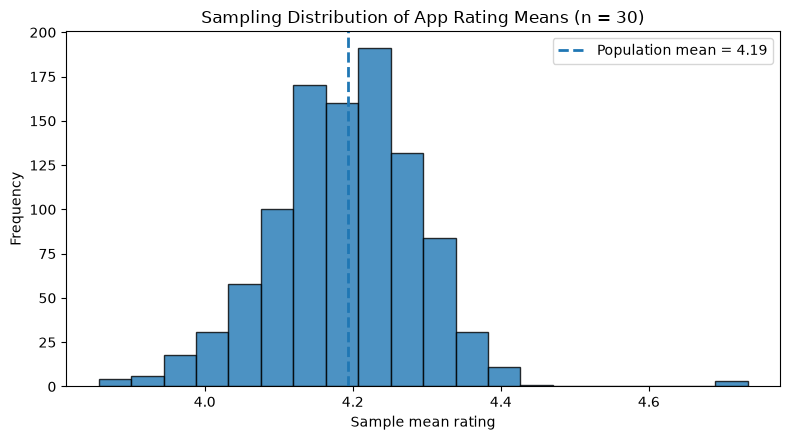

In [446]:
# Histogram of the sampling distribution (one graph, following the reference notebook)

plt.figure(figsize=(8, 4.5))
plt.hist(sample_means_30, bins=20, edgecolor="black", alpha=0.8)
plt.axvline(
    population.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Population mean = {population.mean():.2f}"
)
plt.title("Sampling Distribution of App Rating Means (n = 30)")
plt.xlabel("Sample mean rating")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

### 15.8 Interpretation

The mean of the repeated sample means can be compared with the population mean; the two should be close, although a finite number of random samples may produce a small difference.

The standard deviation of the sample means estimates sampling variability. It is generally expected to be smaller for samples of size 100 than for samples of size 30 because larger samples produce more stable averages.

The histogram shows the distribution of sample means for size 30. The CLT concerns this sampling distribution, not the distribution of the original app ratings.

### 15.9 Observations

1. Compare the mean of the sample means with the population mean.
2. The standard deviation of sample means measures sampling variability.
3. Larger samples are generally expected to produce a narrower sampling distribution.
4. The fixed random seed makes the experiment reproducible.

Use the actual values printed by the notebook when reporting the findings.

### 15.10 Decision and Conclusion

Repeated random sampling demonstrates how sample averages vary and why larger samples generally produce more stable estimates of the population mean.

The histogram is retained because it directly illustrates the sampling distribution and follows the reference notebook's visualisation approach. Other sections use tables and numerical summaries to avoid unnecessary graphs. The fixed random seed makes the experiment reproducible.

## 16. Correlation Analysis

### 16.1 Objective

The objective of this section is to study the relationships between numerical variables in the Google Play Store dataset.

We will analyse the relationship between app ratings, installations, and prices using covariance, Pearson correlation, and Spearman correlation.

### 16.2 Concept

Correlation measures the strength and direction of the relationship between two numerical variables.

**Covariance:** Indicates whether two variables tend to increase or decrease together.

**Pearson Correlation:** Measures the strength and direction of a linear relationship between two variables. Its value ranges from -1 to +1.

**Spearman Correlation:** Measures the strength and direction of a monotonic relationship using the ranks of observations.

Interpretation of correlation values:

- +1: Perfect positive correlation.
- 0: No linear correlation for Pearson.
- -1: Perfect negative correlation.

Correlation does not prove causation. A relationship between two variables does not mean that one causes the other.

### 16.3 Methodology

1. Select Rating, Installs, and Price from the dataset.
2. Ensure that all selected variables have numerical data types.
3. Calculate the covariance matrix.
4. Calculate Pearson correlation coefficients.
5. Calculate Spearman correlation coefficients.
6. Use pairwise correlation results to examine relationships between pairs of variables.

In [447]:
correlation_data = apps[["Rating", "Installs", "Price"]].copy()

correlation_data = correlation_data.apply(
    pd.to_numeric, errors="coerce"
)

print("First five records:")
display(correlation_data.head())

print("\nMissing values:")
display(correlation_data.isnull().sum())

First five records:


,Rating,Installs,Price
0,4.1,10000.0,0.0
1,3.9,500000.0,0.0
2,4.7,5000000.0,0.0
3,4.5,50000000.0,0.0
4,4.3,100000.0,0.0



Missing values:


Rating      1474
Installs       1
Price          1
dtype: int64

In [448]:
covariance_matrix = correlation_data.cov()

print("Covariance Matrix:")
display(covariance_matrix)

Covariance Matrix:


,Rating,Installs,Price
Rating,2.888324e-01,2.414057e+06,-1.784901e-01
Installs,2.414057e+06,7.229992e+15,-1.585318e+07
Price,-1.784901e-01,-1.585318e+07,2.543930e+02


In [449]:
pearson_corr = correlation_data.corr(method="pearson")

print("Pearson Correlation Matrix:")
display(pearson_corr)

Pearson Correlation Matrix:


,Rating,Installs,Price
Rating,1.000000,0.051355,-0.021903
Installs,0.051355,1.000000,-0.011689
Price,-0.021903,-0.011689,1.000000


In [450]:
spearman_corr = correlation_data.corr(method="spearman")

print("Spearman Correlation Matrix:")
display(spearman_corr)

Spearman Correlation Matrix:


,Rating,Installs,Price
Rating,1.000000,0.069546,0.064280
Installs,0.069546,1.000000,-0.242958
Price,0.064280,-0.242958,1.000000


### 16.10 Interpretation

The covariance matrix indicates how numerical variables vary together.

Pearson correlation measures linear relationships, whereas Spearman correlation measures monotonic relationships using ranks.

The correlation matrices present the coefficients in tabular form. Pairwise correlation results help identify the direction and strength of relationships between variables.

Correlation values should be interpreted carefully because extreme values and skewed distributions may influence the results.

### 16.11 Decision

Pearson and Spearman correlation will both be considered to understand relationships between the numerical variables.

The covariance and correlation matrices will be interpreted together rather than relying on a single statistical measure.

No causal relationship will be assumed from correlation alone.

### 16.13 Conclusion

Correlation analysis helps identify relationships between app ratings, installations, and prices.

Using covariance, Pearson correlation, Spearman correlation, correlation matrix, and pairwise correlation results provides a better understanding of the relationships within the Google Play Store dataset.

# 17. Further Data-Quality Checks

## 17.1 Objective

Check whether important numerical fields contain values outside their expected ranges and verify the integrity of the app-to-review relationship.

## 17.2 Methodology

The checks below examine app ratings outside the 1–5 scale, negative installation or price values, missing parsed update dates, duplicate rows and review app names that do not appear in the Apps dataset.

These checks identify records for investigation; they do not automatically delete or modify them.

In [451]:
# Checking numerical validity and key integrity

invalid_rating_count = (
    (apps["Rating"] < 1) | (apps["Rating"] > 5)
).sum()

negative_installs_count = (apps["Installs"] < 0).sum()
negative_price_count = (apps["Price"] < 0).sum()
invalid_update_dates = apps["Last Updated"].isna().sum()

review_apps_not_in_apps = (
    set(reviews["App"].dropna()) - set(apps["App"].dropna())
)

data_quality_summary = pd.Series({
    "Duplicate app rows": apps.duplicated().sum(),
    "Duplicate review rows": reviews.duplicated().sum(),
    "Ratings outside 1–5": invalid_rating_count,
    "Negative install values": negative_installs_count,
    "Negative price values": negative_price_count,
    "Missing/invalid update dates": invalid_update_dates,
    "Review app names absent from Apps dataset": len(review_apps_not_in_apps)
}, name="Count")

display(data_quality_summary.to_frame())

,Count
Duplicate app rows,483
Duplicate review rows,33616
Ratings outside 1–5,1
Negative install values,0
Negative price values,0
Missing/invalid update dates,1
Review app names absent from Apps dataset,54


## 17.3 Interpretation and Decision

The checks identify one app rating outside the expected 1–5 range and one update date that could not be parsed. They also quantify duplicate records and review app names that have no matching app name in the Apps dataset.

A non-matching app name is not automatically a data-entry error; it may reflect a different app listing or inconsistent naming between source files. The notebook retains these records and reports the issue rather than silently deleting data.

**Conclusion:** The final quality checks document potential issues and preserve traceability to the supplied source data.

# 18. Findings and Observations

## Objective

Summarise the findings from data-quality checks, feature engineering, category summaries, integration and statistical analysis.

## Findings to Report

1. **Dataset structure:** The project uses application-level and review-level datasets with different row counts.
2. **Data quality:** Missing values, duplicates and data-type issues are measured before cleaning decisions.
3. **Feature engineering:** Price, installation and rating categories and update year are derived from existing fields.
4. **Category analysis:** Grouping compares app counts, ratings and installation statistics.
5. **Review integration:** Review records are aggregated by app before merging to avoid multiplying app rows.
6. **Descriptive analysis:** Central tendency, dispersion, percentiles, skewness and kurtosis summarise numerical fields.
7. **Sampling:** Repeated samples demonstrate how sample means vary with sample size.
8. **Association:** Covariance, Pearson and Spearman correlation measure relationships between numerical variables.

## Interpretation and Decision

Use the actual values printed in the notebook when identifying the largest categories, skewed variables, strongest associations and data-quality issues. Include only numerical claims supported by the outputs. Correlation does not establish causation.

## Conclusion

The findings bring together the dataset exploration and statistical techniques used in this project.

## 19. Limitations and Future Scope

### Limitations

1. The files represent a particular data snapshot and may not reflect current Google Play Store trends.
2. Missing values and duplicate records may affect some summaries.
3. Some numerical columns require conversion from text, and invalid values may become missing.
4. Some apps have no matching review information in the supplied Reviews dataset.
5. Sentiment labels depend on the original dataset's processing method.
6. The analysis identifies patterns and associations but does not establish cause and effect.
7. The Empirical Rule is most suitable for approximately normal distributions and may not fit bounded or skewed variables.

### Future Scope

1. Use more recent datasets to examine changes over time.
2. Explore app size, content rating, genre and update frequency.
3. Apply NLP to review text and compare text-derived sentiment with supplied labels.
4. Study review volume and sentiment across categories and price groups.
5. Investigate outliers and duplicates using documented rules.
6. Add focused visualisations or predictive models where they answer a clear research question.

## 20. Final Conclusion

This project applied Exploratory Data Analysis to the Google Play Store Apps and User Reviews datasets. It covered dataset understanding, data-quality assessment, type conversion, feature engineering, grouping and aggregation, pivot tables, crosstabulation, data reshaping and data integration.

Descriptive statistics, distribution analysis, the Empirical Rule, repeated sampling, the Central Limit Theorem and correlation were used to examine ratings, installations and prices. Review information was aggregated at application level before merging so that the different granularities of the two source files were handled appropriately.

The notebook retains one focused histogram in the CLT section to visualise the sampling distribution of app-rating means for samples of size 30. Other findings are presented through tables and numerical summaries.

Overall, the project demonstrates a structured EDA workflow using Python, Pandas and NumPy. Conclusions describe patterns in the supplied data snapshot; they do not represent current Google Play Store conditions or establish causal relationships.